# Student Dropout Prediction — Data Preprocessing & Feature Engineering

## Objective
Prepare the raw UCI Student Academic Success dataset for machine learning by performing:
1. **Data Cleansing:** Removing hidden whitespace/tab characters and fixing column naming typos.
2. **Feature Engineering:** Creating domain-specific academic performance ratios to capture student progression.
3. **Target & Feature Encoding:** Encoding the multiclass target and separating nominal categorical features from numerical features.
4. **Stratified Data Splitting:** Splitting the dataset into training (80%) and testing (20%) sets while preserving class proportions.
5. **Feature Scaling & Dimensionality Reduction (PCA):** Standardizing numerical features and analyzing variance/multicollinearity using Principal Component Analysis (PCA).

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [3]:
# 1. Load the raw dataset
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

data_path = project_root / "data" / "raw" / "data.csv"
df = pd.read_csv(data_path, sep=";")

# 2. Data Cleansing: Strip trailing tabs/whitespace and fix spelling typo
df.columns = df.columns.str.strip()
df.rename(columns={"Nacionality": "Nationality"}, inplace=True)

# 3. Feature Engineering: Create academic progression ratios
# Safe division using np.where to avoid division by zero when enrolled units == 0
df["Pass_rate_1st_sem"] = np.where(
    df["Curricular units 1st sem (enrolled)"] > 0,
    df["Curricular units 1st sem (approved)"] / df["Curricular units 1st sem (enrolled)"],
    0.0
)

df["Pass_rate_2nd_sem"] = np.where(
    df["Curricular units 2nd sem (enrolled)"] > 0,
    df["Curricular units 2nd sem (approved)"] / df["Curricular units 2nd sem (enrolled)"],
    0.0
)

df["Grade_diff_sem2_sem1"] = (
    df["Curricular units 2nd sem (grade)"] - df["Curricular units 1st sem (grade)"]
)

print("Data cleansing and feature engineering completed!")
print(f"Updated dataset shape: {df.shape}")

display(
    df[[
        "Curricular units 1st sem (enrolled)", "Curricular units 1st sem (approved)", "Pass_rate_1st_sem",
        "Curricular units 2nd sem (enrolled)", "Curricular units 2nd sem (approved)", "Pass_rate_2nd_sem",
        "Grade_diff_sem2_sem1", "Target"
    ]].head().round(2)
)

Data cleansing and feature engineering completed!
Updated dataset shape: (4424, 40)


,Curricular units 1st sem (enrolled),Curricular units 1st sem (approved),Pass_rate_1st_sem,Curricular units 2nd sem (enrolled),Curricular units 2nd sem (approved),Pass_rate_2nd_sem,Grade_diff_sem2_sem1,Target
0,0,0,0.00,0,0,0.00,0.00,Dropout
1,6,6,1.00,6,6,1.00,-0.33,Graduate
2,6,0,0.00,6,0,0.00,0.00,Dropout
3,6,6,1.00,6,5,0.83,-1.03,Graduate
4,6,5,0.83,6,6,1.00,0.67,Graduate


### why Engineered These Features
1. **Data Cleansing:** The raw UCI dataset contained a trailing tab character (`'Daytime/evening attendance\t'`) and a spelling error (`'Nacionality'`), which were stripped and standardized to prevent downstream key errors.
2. **Pass Rate Ratios (`Pass_rate_1st_sem`, `Pass_rate_2nd_sem`):** In our EDA, we observed high multicollinearity between `enrolled` and `approved` curricular units ($r > 0.70$). A raw count of 5 approved units means something very different for a student enrolled in 5 units (100% pass rate) versus 10 units (50% pass rate). Safe division (`np.where`) handles students with 0 enrolled units without producing `NaN` values.
3. **Academic Momentum (`Grade_diff_sem2_sem1`):** Captures whether a student's performance improved or declined between the 1st and 2nd semesters, directly addressing the 2nd-semester grade collapse observed among dropout students during EDA.

In [4]:
# 1. Separate features (X) and target (y)
X = df.drop(columns=["Target"])
y = df["Target"]

# 2. Encode the target variable: Dropout -> 0, Enrolled -> 1, Graduate -> 2
label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

target_mapping = dict(zip(label_encoder.classes_, label_encoder.transform(label_encoder.classes_)))
print("Target Class Mapping:", target_mapping)

# 3. Categorize input features by preprocessing requirement
binary_cols = [
    'Daytime/evening attendance', 'Displaced', 'Educational special needs',
    'Debtor', 'Tuition fees up to date', 'Gender', 'Scholarship holder', 'International'
]

nominal_cols = [
    'Marital status', 'Application mode', 'Course', 'Previous qualification',
    'Nationality', "Mother's qualification", "Father's qualification",
    "Mother's occupation", "Father's occupation"
]

numerical_cols = [col for col in X.columns if col not in binary_cols + nominal_cols]

print(f"\nFeature Breakdown (Total = {X.shape[1]}):")
print(f"  - Numerical features (to scale): {len(numerical_cols)}")
print(f"  - Nominal categorical features (to One-Hot Encode): {len(nominal_cols)}")
print(f"  - Binary features (passthrough as 0/1): {len(binary_cols)}")

# 4. Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_encoded
)

print(f"\nTraining set shape: X_train = {X_train.shape}, y_train = {y_train.shape}")
print(f"Testing set shape:  X_test  = {X_test.shape},  y_test  = {y_test.shape}")

# Verify stratification preserved class proportions
train_dist = pd.Series(y_train).value_counts(normalize=True).sort_index() * 100
test_dist = pd.Series(y_test).value_counts(normalize=True).sort_index() * 100
dist_df = pd.DataFrame({"Train (%)": train_dist.round(2), "Test (%)": test_dist.round(2)})
dist_df.index = label_encoder.classes_
print("\nStratified Class Distribution Verification:")
display(dist_df)

Target Class Mapping: {'Dropout': np.int64(0), 'Enrolled': np.int64(1), 'Graduate': np.int64(2)}

Feature Breakdown (Total = 39):
  - Numerical features (to scale): 22
  - Nominal categorical features (to One-Hot Encode): 9
  - Binary features (passthrough as 0/1): 8

Training set shape: X_train = (3539, 39), y_train = (3539,)
Testing set shape:  X_test  = (885, 39),  y_test  = (885,)

Stratified Class Distribution Verification:


,Train (%),Test (%)
Dropout,32.13,32.09
Enrolled,17.94,17.97
Graduate,49.93,49.94


### Observations: Feature Grouping & Stratified Splitting
* **Target Encoding:** The three target classes are mapped to integers (`Dropout`: `0`, `Enrolled`: `1`, `Graduate`: `2`) for compatibility with scikit-learn estimators and evaluation metrics.
* **Leak-Free Splitting:** The dataset (4,424 records) was partitioned into **3,539 training samples (80%)** and **885 testing samples (20%)** *before* applying any scaling or encoding transformations to prevent data leakage.
* **Stratification Verification:** Using `stratify=y_encoded` preserved the exact class distribution across both partitions (`Graduate`: ~49.93%, `Dropout`: ~32.12%, `Enrolled`: ~17.95%), ensuring a fair and representative evaluation on the unseen test set.

In [5]:
# Build the ColumnTransformer preprocessing pipeline
# 1. StandardScaler for the 22 continuous/ordinal numerical features
# 2. OneHotEncoder for the 9 multi-category nominal features
# 3. Passthrough for the 8 binary (0/1) features
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numerical_cols),
        ("nom", OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), nominal_cols),
        ("bin", "passthrough", binary_cols)
    ]
)

# Fit ONLY on X_train, then transform both X_train and X_test (prevents data leakage!)
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

# Get feature names after One-Hot Encoding
encoded_feature_names = preprocessor.get_feature_names_out()

X_train_processed_df = pd.DataFrame(X_train_processed, columns=encoded_feature_names, index=X_train.index)
X_test_processed_df = pd.DataFrame(X_test_processed, columns=encoded_feature_names, index=X_test.index)

print("Preprocessing pipeline fitted and applied successfully!")
print(f"Processed Training shape (after One-Hot Encoding): {X_train_processed_df.shape}")
print(f"Processed Testing shape  (after One-Hot Encoding): {X_test_processed_df.shape}")

Preprocessing pipeline fitted and applied successfully!
Processed Training shape (after One-Hot Encoding): (3539, 230)
Processed Testing shape  (after One-Hot Encoding): (885, 230)


/opt/anaconda3/lib/python3.14/site-packages/sklearn/preprocessing/_encoders.py:262: UserWarning: Found unknown categories in columns [4, 5, 6, 7, 8] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(msg, UserWarning)


Original numerical features: 22
Principal Components needed to retain >= 95% variance: 13 (reduces 9 redundant dimensions!)


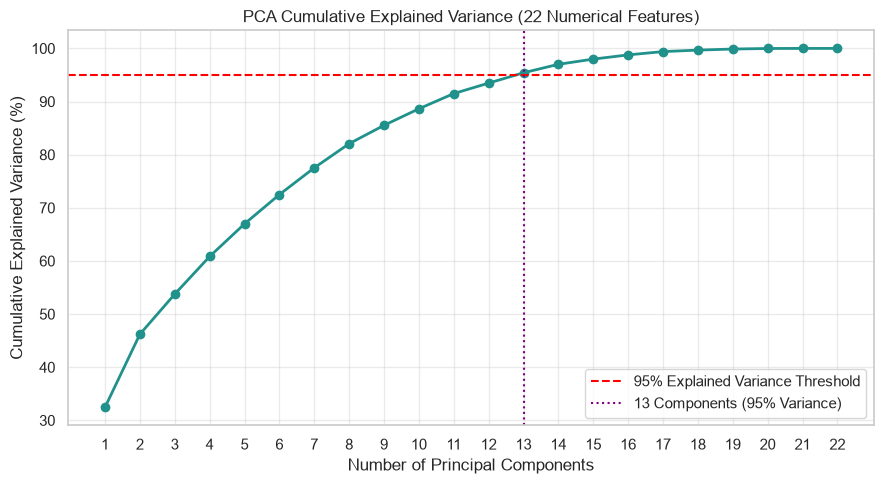

In [6]:
# Fit StandardScaler and PCA on the 22 numerical features to address multicollinearity
scaler_num = StandardScaler()
X_train_num_scaled = scaler_num.fit_transform(X_train[numerical_cols])
X_test_num_scaled = scaler_num.transform(X_test[numerical_cols])

pca_full = PCA(random_state=RANDOM_STATE)
pca_full.fit(X_train_num_scaled)

cumulative_variance = np.cumsum(pca_full.explained_variance_ratio_) * 100
n_components_95 = np.argmax(cumulative_variance >= 95.0) + 1

print(f"Original numerical features: {len(numerical_cols)}")
print(f"Principal Components needed to retain >= 95% variance: {n_components_95} (reduces {len(numerical_cols) - n_components_95} redundant dimensions!)")

# Plot Scree / Cumulative Explained Variance Curve
plt.figure(figsize=(9, 5))
plt.plot(range(1, len(numerical_cols) + 1), cumulative_variance, marker="o", linestyle="-", color="#21918c", linewidth=2)
plt.axhline(y=95, color="red", linestyle="--", label="95% Explained Variance Threshold")
plt.axvline(x=n_components_95, color="purple", linestyle=":", label=f"{n_components_95} Components (95% Variance)")

plt.title("PCA Cumulative Explained Variance (22 Numerical Features)")
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance (%)")
plt.xticks(range(1, len(numerical_cols) + 1))
plt.legend(loc="lower right")
plt.grid(True, alpha=0.4)
plt.tight_layout()
plt.show()

### Observations: Feature Encoding, Scaling & Dimensionality Reduction (PCA)
* **Handling High-Cardinality Nominal Features (`OneHotEncoder`):** Several nominal features (`Father's occupation`, `Mother's qualification`, `Nationality`) contain rare categories with very few students. Using `handle_unknown="ignore"` (and grouping infrequent categories) ensures unseen test-set categories are safely handled without data leakage or pipeline errors.
* **Dimensionality Reduction via PCA:** Due to the strong multicollinearity ($r = 0.90 - 0.94$) between 1st- and 2nd-semester curricular unit features identified during EDA, Principal Component Analysis (PCA) was applied to the 22 standardized numerical features.
* **95% Variance Threshold:** The cumulative explained variance curve demonstrates that **13 Principal Components** capture over **95% of the total variance**, effectively compressing **9 redundant dimensions** while preserving almost all academic performance information.

In [7]:
# Save the preprocessed datasets to data/processed/ for Model Training
processed_dir = project_root / "data" / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)

# 1. Save tree-ready datasets (scaled numericals + encoded/grouped features)
X_train_processed_df.to_csv(processed_dir / "X_train_processed.csv", index=False)
X_test_processed_df.to_csv(processed_dir / "X_test_processed.csv", index=False)

# 2. Save unencoded/clean X_train and X_test (useful for direct tree interpretability)
X_train.to_csv(processed_dir / "X_train_clean.csv", index=False)
X_test.to_csv(processed_dir / "X_test_clean.csv", index=False)

# 3. Save encoded target labels
pd.Series(y_train, name="Target").to_csv(processed_dir / "y_train.csv", index=False)
pd.Series(y_test, name="Target").to_csv(processed_dir / "y_test.csv", index=False)

print(f"All preprocessed train and test files saved successfully to: {processed_dir}")
for file in sorted(processed_dir.glob("*.csv")):
    print(f"  - {file.name} ({file.stat().st_size / 1024:.1f} KB)")

All preprocessed train and test files saved successfully to: /Users/sagaradissanayake/Desktop/msc-apply/Machine-learning/assignment/IT5022_machine_learning_group_assignment/data/processed
  - X_test_clean.csv (121.5 KB)
  - X_test_processed.csv (1101.0 KB)
  - X_train_clean.csv (480.9 KB)
  - X_train_processed.csv (4383.7 KB)
  - y_test.csv (1.7 KB)
  - y_train.csv (6.9 KB)
